# Multivariate forecasting of treatment-plant operations

This report summarizes the saved short-history, expanded-history and hyperparameter-tuned experiments. It uses real operational observations, including abrupt changes and missing readings. Large observations are preserved; magnitude alone is not evidence of a measurement fault.

**Finding:** methanol dosing has the most consistent predictive performance. Ammonium and airflow generalization remains limited. Increasing history helped several models; tuning validation performance did not consistently improve the fixed test period.

Run all cells to reproduce tables and presentation figures from the portable result snapshots in `docs/assets/current_forecasts`. No model training, database access, download or source-data editing occurs. Figure and summary exports in that folder are replaced when rerun. These results supersede the older seven-day SQL slide material, whose metrics must not be mixed with this experiment.

In [1]:
from pathlib import Path
import hashlib
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
from IPython.display import display, Markdown

ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / 'src/training/train.py').exists())
ASSETS = ROOT / 'docs/assets/current_forecasts'
provenance = json.loads((ASSETS / 'provenance.json').read_text())
for filename, expected in provenance['snapshot_sha256'].items():
    assert hashlib.sha256((ASSETS / filename).read_bytes()).hexdigest() == expected, filename
metrics = pd.read_csv(ASSETS / 'experiment_metrics.csv')
ORDER = ['eff_nh3_n', 'eff_no3_n', 'a1_ch3oh_flow', 'a2_ch3oh_flow', 'a1_air_flow', 'a2_air_flow']
LABELS = dict(zip(ORDER, ['Effluent ammonium', 'Effluent nitrate', 'A1 methanol dosing', 'A2 methanol dosing', 'A1 airflow', 'A2 airflow']))
ALGORITHMS = ['Ridge', 'Random Forest', 'XGBoost', 'LSTM']
plt.rcParams.update({'figure.dpi': 120, 'font.size': 10, 'axes.spines.top': False, 'axes.spines.right': False})
print('Snapshot hashes verified. Reporting saved results only.')

Snapshot hashes verified. Reporting saved results only.


## Data, preparation and evaluation

| Item | Definition |
|---|---|
| Expanded source | Local full CSV snapshot, 24 March 2026 13:00 through 23 April 2026 23:59 |
| Training | Available March 24–April 17 history; future training labels must occur before April 18 |
| Validation | April 18–20; future validation labels must occur before April 21 |
| Test | Rolling forecast origins April 21–23; exact observed labels one hour later within the available window |
| Preparation | Notebook 02 policy, applied to expanded history: flow carry limit 2 min, chemistry 5 min, MLSS 15 min |
| Input features | Workbook checkmarks plus target history; constant/unobserved/unsupported training features excluded |
| Sequence | 12 samples spaced 20 min apart, spanning 3 h 40 min, ending at each origin |
| Target | Exact observed minute reading at origin +60 min; **not** a 20-minute mean |
| Missing values | Filled estimates excluded from future labels; remaining input imputation/scaling fitted on training only; missingness channels included |
| Algorithms | Ridge, Random Forest, XGBoost, LSTM |
| Selection | Minimum validation MSE, equivalent to maximum R² for fixed nonconstant validation labels; no train/validation refit |

Time stamps remain timezone-naive source times. Earlier test observations may enter later forecast histories when available. This is rolling forecasting, rather than one forecast of the whole test period at its start.

The original ten-day inputs came from notebook 02, not notebook 01's unlimited-forward-fill preparation. Test inputs, fill masks, origins and labels were checked against the earlier run. The test period has now been inspected repeatedly: it was excluded from automated selection, but a new later period is needed for independent confirmation.

MAE and RMSE retain the recorded target units. R² compares squared error with the retrospective mean of the evaluated split; negative values indicate worse squared error than that reference. R² is undefined for a constant target. The latest runs contain **no persistence baseline**, so improvement over persistence is not claimed. Flow units follow the workbook and need instrument-scaling confirmation.

In [2]:
features = json.loads((ASSETS / 'feature_configuration.json').read_text())
coverage = pd.DataFrame([{'Target': LABELS[f['model']], 'Training sequences': f['counts']['train'],
    'Validation sequences': f['counts']['validation'], 'Test sequences': f['counts']['test'],
    'Retained sensors': len(f['features'])} for f in features])
display(coverage)
for f in features:
    display(Markdown('**' + LABELS[f['model']] + '**: ' + ', '.join('`' + x + '`' for x in f['features']) +
        '. Excluded constant/unobserved sensors: ' + (', '.join(f['excluded']) or 'none') + '.'))
display(Markdown('Airflow target mappings follow the confirmed headings: A1 = `Q_A1_air`, A2 = `Q_A2_air`; inconsistent green workbook marks do not override them.'))

,Target,Training sequences,Validation sequences,Test sequences,Retained sensors
0,Effluent ammonium,1733,213,211,15
1,Effluent nitrate,1733,213,211,19
2,A1 methanol dosing,1746,213,213,9
3,A2 methanol dosing,1746,213,213,9
4,A1 airflow,1730,212,211,9
5,A2 airflow,1729,212,211,10


**Effluent ammonium**: `A1_Qin`, `A2_Qin`, `A1_COD_in`, `A2_COD_in`, `A1_O_PH`, `A1_O_ORP`, `A1_O_DO`, `A1_O_MLSS`, `A2_O_PH`, `A2_O_ORP`, `A2_O_DO`, `A2_O_MLSS`, `Q_A1_air`, `Q_A2_air`, `Eff_NH4_N`. Excluded constant/unobserved sensors: A1_NH3_N, A2_NH3_N.

**Effluent nitrate**: `A1_Qin`, `A2_Qin`, `A1_COD_in`, `A1_FQ_CH3OH`, `A1_Q_r1`, `A2_COD_in`, `A2_Q_r1`, `A2_FQ_CH3OH`, `A1_A_PH`, `A1_A_ORP`, `A1_A_DO`, `A1_A_MLSS`, `A2_A_PH`, `A2_A_ORP`, `A2_A_DO`, `A2_A_MLSS`, `Q_A1_air`, `Q_A2_air`, `Eff_NH4_N`. Excluded constant/unobserved sensors: A1_NH3_N, A2_NH3_N, Eff_NO3_N.

**A1 methanol dosing**: `A1_Qin`, `A1_COD_in`, `A1_FQ_CH3OH`, `A1_Q_r1`, `A1_A_PH`, `A1_A_ORP`, `A1_A_DO`, `A1_A_MLSS`, `Eff_NH4_N`. Excluded constant/unobserved sensors: A1_NH3_N, Eff_NO3_N.

**A2 methanol dosing**: `A2_Qin`, `A2_COD_in`, `A2_Q_r1`, `A2_FQ_CH3OH`, `A2_A_PH`, `A2_A_ORP`, `A2_A_DO`, `A2_A_MLSS`, `Eff_NH4_N`. Excluded constant/unobserved sensors: A2_NH3_N, Eff_NO3_N.

**A1 airflow**: `A1_Qin`, `A1_FQ_CH3OH`, `A1_Q_r1`, `A1_O_PH`, `A1_O_ORP`, `A1_O_DO`, `A1_O_MLSS`, `Q_A2_air`, `Q_A1_air`. Excluded constant/unobserved sensors: A1_NH3_N.

**A2 airflow**: `A2_Qin`, `A2_COD_in`, `A2_Q_r1`, `A2_FQ_CH3OH`, `A2_O_PH`, `A2_O_ORP`, `A2_O_DO`, `A2_O_MLSS`, `Eff_NH4_N`, `Q_A2_air`. Excluded constant/unobserved sensors: A2_NH3_N.

Airflow target mappings follow the confirmed headings: A1 = `Q_A1_air`, A2 = `Q_A2_air`; inconsistent green workbook marks do not override them.

## Model selection and headline results

Select each target's algorithm using validation RMSE only, with stable first-listed tie handling. All test scores below belong to those validation-selected models. A model with the best test R² may differ; test rankings are descriptive and do not select the headline model.

,algorithm,n,MAE,RMSE,unit,Test R2,Training R2,Validation R2,Target
0,XGBoost,211,0.009132,0.011110,mg-N/L,-0.000066,0.472094,-0.100761,Effluent ammonium
1,Ridge,211,0.000000,0.000000,mg-N/L,NaN,NaN,NaN,Effluent nitrate
2,Ridge,213,17.871515,26.470019,m3/hour,0.730146,0.831004,0.788096,A1 methanol dosing
3,XGBoost,213,13.529343,19.716478,m3/hour,0.693398,0.944996,0.700538,A2 methanol dosing
4,LSTM,211,2.025027,3.646666,m3/min,-0.287165,0.838000,0.821176,A1 airflow
5,LSTM,211,1.899255,2.971203,m3/min,-0.015808,0.879062,0.920882,A2 airflow


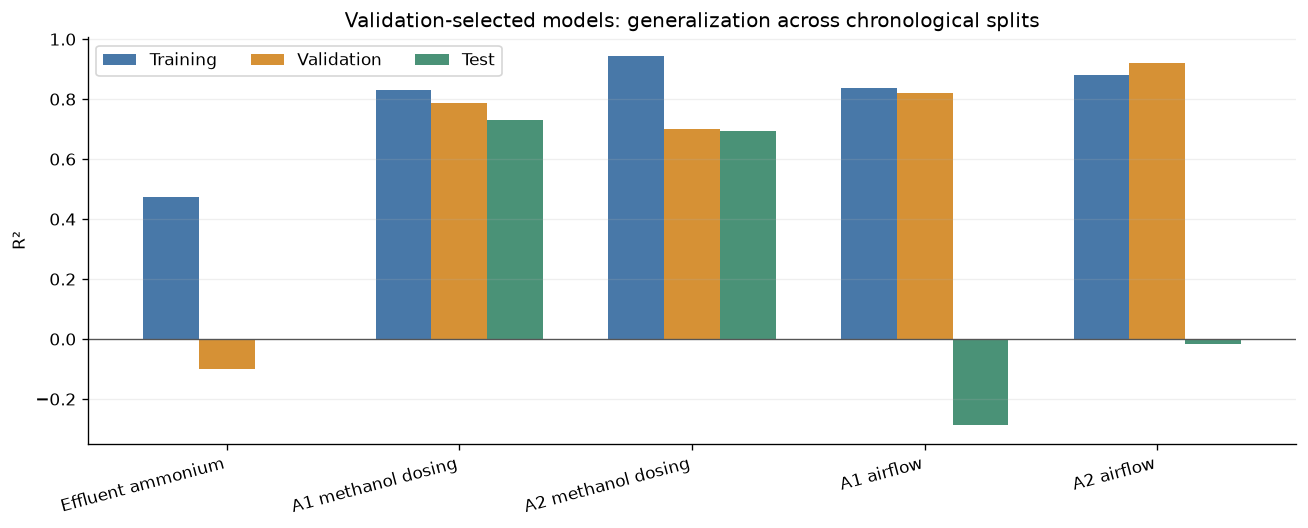

In [3]:
def validation_winners(frame):
    v = frame.loc[frame['split'].eq('validation')].copy()
    return v.loc[v.groupby('model', sort=False)['RMSE'].idxmin(), ['model', 'algorithm']]

tuned = metrics.loc[metrics.experiment.eq('Tuned history')].copy()
winners = validation_winners(tuned)
selected = tuned.merge(winners, on=['model', 'algorithm'], validate='many_to_one')
r2 = selected.pivot(index=['model', 'algorithm'], columns='split', values='R2').rename(columns={
    'train': 'Training R2', 'validation': 'Validation R2', 'test': 'Test R2'})
headline = selected.loc[selected['split'].eq('test'), ['model', 'algorithm', 'n', 'MAE', 'RMSE', 'unit']].merge(r2.reset_index(), on=['model', 'algorithm'])
headline = headline.set_index('model').loc[ORDER].reset_index()
headline.to_csv(ASSETS / 'headline_metrics.csv', index=False)
display(headline.assign(Target=headline.model.map(LABELS)).drop(columns='model').round(6))

fig, ax = plt.subplots(figsize=(11, 4.5))
varying = headline.loc[headline['Test R2'].notna()]
x = np.arange(len(varying))
for offset, column, color in [(-.24, 'Training R2', '#4878A8'), (0, 'Validation R2', '#D69135'), (.24, 'Test R2', '#4A9277')]:
    ax.bar(x + offset, varying[column], width=.24, label=column.replace(' R2', ''), color=color)
ax.axhline(0, color='#555555', lw=.8)
ax.set_xticks(x, varying.model.map(LABELS), rotation=15, ha='right')
ax.set(ylabel='R²', title='Validation-selected models: generalization across chronological splits')
ax.legend(ncol=3)
ax.grid(axis='y', alpha=.2)
fig.tight_layout()
fig.savefig(ASSETS / 'selected_r2_comparison.png', dpi=170)
plt.show()

## Effect of historical expansion and hyperparameter tuning

The short run begins April 14; expanded and tuned runs begin March 24. All keep validation April 18–20 and testing April 21–23. Select the algorithm independently by validation within each experiment. This comparison can change the algorithm as well as its settings. The complete table below also allows comparisons within the same algorithm.

Tuning searched Ridge regularization, Random Forest structure and feature sampling, XGBoost structure/learning rate/regularization/sampling, and LSTM width/learning rate/weight decay. Existing models remained candidates. Validation error matched or improved for every algorithm, but test performance did not consistently improve. Nitrate has undefined R² and cannot support an R² optimization claim.

In [4]:
experiment_rows = []
for experiment, frame in metrics.groupby('experiment', sort=False):
    chosen = frame.merge(validation_winners(frame), on=['model', 'algorithm'])
    experiment_rows.append(chosen.loc[chosen['split'].eq('test'), ['model', 'algorithm', 'R2', 'RMSE', 'MAE', 'experiment']])
comparison = pd.concat(experiment_rows, ignore_index=True)
display(comparison.assign(Target=comparison.model.map(LABELS)).drop(columns='model').round(6))
display(metrics.pivot_table(index=['model', 'algorithm'], columns=['experiment', 'split'], values='R2', dropna=False).round(4))
comparison.to_csv(ASSETS / 'validation_selected_experiment_comparison.csv', index=False)

old_validation = metrics.query("experiment == 'Expanded history' and split == 'validation'")
new_validation = tuned.query("split == 'validation'")
check = old_validation.merge(new_validation, on=['model', 'algorithm'], suffixes=('_old', '_new'), validate='one_to_one')
assert (check.RMSE_new <= check.RMSE_old + 1e-7).all()
display(Markdown('**Verified:** no algorithm has a higher validation RMSE after tuning. This does not imply lower test error.'))

,algorithm,R2,RMSE,MAE,experiment,Target
0,LSTM,-0.322172,0.012774,0.010797,Short history,Effluent ammonium
1,Ridge,NaN,0.000000,0.000000,Short history,Effluent nitrate
2,Random Forest,0.530597,34.911021,18.865402,Short history,A1 methanol dosing
3,Random Forest,0.486737,25.510090,19.969092,Short history,A2 methanol dosing
4,LSTM,-0.086962,3.351090,1.773468,Short history,A1 airflow
5,LSTM,0.435590,2.214745,1.336876,Short history,A2 airflow
6,XGBoost,-0.028339,0.011266,0.009082,Expanded history,Effluent ammonium
7,Ridge,NaN,0.000000,0.000000,Expanded history,Effluent nitrate
8,Ridge,0.733161,26.321733,17.741488,Expanded history,A1 methanol dosing
9,XGBoost,0.704810,19.346057,13.407529,Expanded history,A2 methanol dosing


experiment                  Expanded history                    Short history  \
split                                   test   train validation          test   
model         algorithm                                                         
a1_air_flow   LSTM                   -0.2872  0.8380     0.8212       -0.0870   
              Random Forest           0.1401  0.8719    -2.8774       -0.6909   
              Ridge                   0.2108  0.6800     0.5955       -0.6885   
              XGBoost                 0.0861  0.8596    -6.0289       -0.3396   
a1_ch3oh_flow LSTM                    0.7427  0.8310     0.7134        0.5630   
              Random Forest           0.6806  0.9243     0.6220        0.5306   
              Ridge                   0.7332  0.8309     0.7878       -0.4959   
              XGBoost                 0.7772  0.8784     0.7104        0.5699   
a2_air_flow   LSTM                    0.0129  0.9085     0.9192        0.4356   
              Random Forest           0.5027  0.9269     0.7282        0.3968   
              Ridge                   0.3885  0.7836     0.7491        0.0133   
              XGBoost                -0.0406  0.9020     0.2894       -0.0905   
a2_ch3oh_flow LSTM                    0.6150  0.8085     0.5711        0.1859   
              Random Forest           0.5864  0.9569     0.6668        0.4867   
              Ridge                   0.6237  0.8037     0.6250       -0.4062   
              XGBoost                 0.7048  0.8558     0.6817        0.2850   
eff_nh3_n     LSTM                   -4.7935  0.1021    -1.5813       -0.3222   
              Random Forest          -0.0981  0.7769    -1.9926       -0.1889   
              Ridge                -122.0732  0.4216   -91.7987       -0.2404   
              XGBoost                -0.0283  0.8765    -0.2012       -0.0663   
eff_no3_n     LSTM                       NaN     NaN        NaN           NaN   
              Random Forest              NaN     NaN        NaN           NaN   
              Ridge                      NaN     NaN        NaN           NaN   
              XGBoost                    NaN     NaN        NaN           NaN   

experiment                                     Tuned history          \
split                         train validation          test   train   
model         algorithm                                                
a1_air_flow   LSTM           0.6572     0.5514       -0.2872  0.8380   
              Random Forest  0.8939    -0.8526        0.2294  0.8132   
              Ridge          0.6248    -1.7128        0.2402  0.6721   
              XGBoost        0.9578    -7.4229        0.0720  0.6773   
a1_ch3oh_flow LSTM           0.6142     0.5211        0.7006  0.8111   
              Random Forest  0.9541     0.6714        0.7930  0.8941   
              Ridge          0.7855     0.2441        0.7301  0.8310   
              XGBoost        0.9594     0.6504        0.7062  0.9818   
a2_air_flow   LSTM           0.5435     0.1173       -0.0158  0.8791   
              Random Forest  0.8885    -0.7203        0.4915  0.8867   
              Ridge          0.7829    -0.2024        0.3714  0.7840   
              XGBoost        0.9974    -6.4208        0.2856  0.7082   
a2_ch3oh_flow LSTM           0.5844     0.3520        0.5951  0.8044   
              Random Forest  0.9234     0.4656        0.6808  0.8984   
              Ridge          0.7808     0.1195        0.6246  0.8038   
              XGBoost        0.9238     0.3081        0.6934  0.9450   
eff_nh3_n     LSTM           0.1487    -0.0120      -19.3531  0.0293   
              Random Forest  0.5620    -0.0220      -32.7704  0.3657   
              Ridge          0.2162    -0.3735      -16.6265  0.0131   
              XGBoost        0.8684    -0.0600       -0.0001  0.4721   
eff_no3_n     LSTM              NaN        NaN           NaN     NaN   
              Random Forest     NaN        NaN           NaN     NaN   
            

**Verified:** no algorithm has a higher validation RMSE after tuning. This does not imply lower test error.

## Test forecasts for all targets

Black is the observed future reading. Colored lines show each tuned algorithm; the validation-selected model is emphasized. The horizontal axis is the **future label time**, not the forecast origin. All algorithms share the same test labels within each target. Large errors remain visible; no clipping or removal is applied.

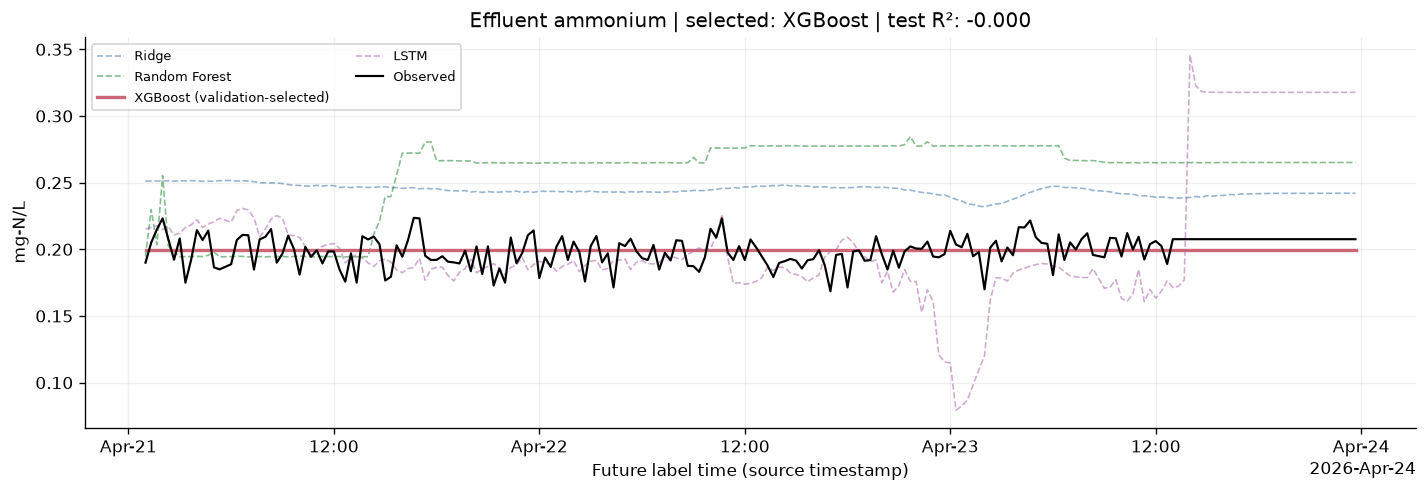

,algorithm,n,MAE,RMSE,R2,unit
194,Ridge,211,0.045018,0.046641,-16.626516,mg-N/L
197,Random Forest,211,0.058971,0.064558,-32.770444,mg-N/L
200,XGBoost,211,0.009132,0.011110,-0.000066,mg-N/L
203,LSTM,211,0.033479,0.050119,-19.353086,mg-N/L


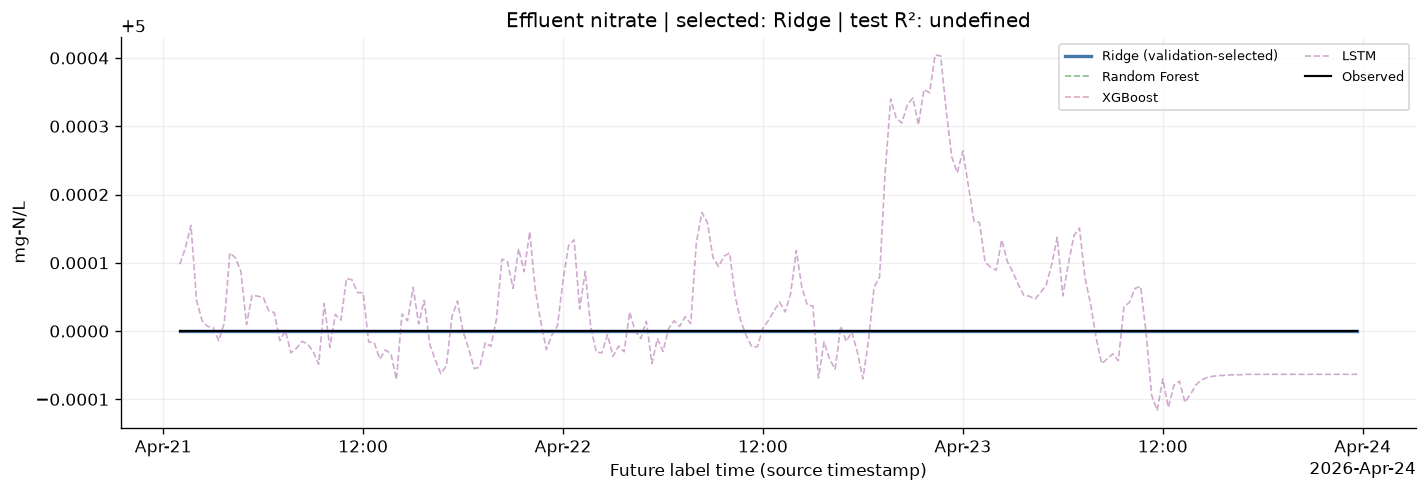

,algorithm,n,MAE,RMSE,R2,unit
206,Ridge,211,0.000000,0.000000,NaN,mg-N/L
209,Random Forest,211,0.000000,0.000000,NaN,mg-N/L
212,XGBoost,211,0.000000,0.000000,NaN,mg-N/L
215,LSTM,211,0.000075,0.000108,NaN,mg-N/L


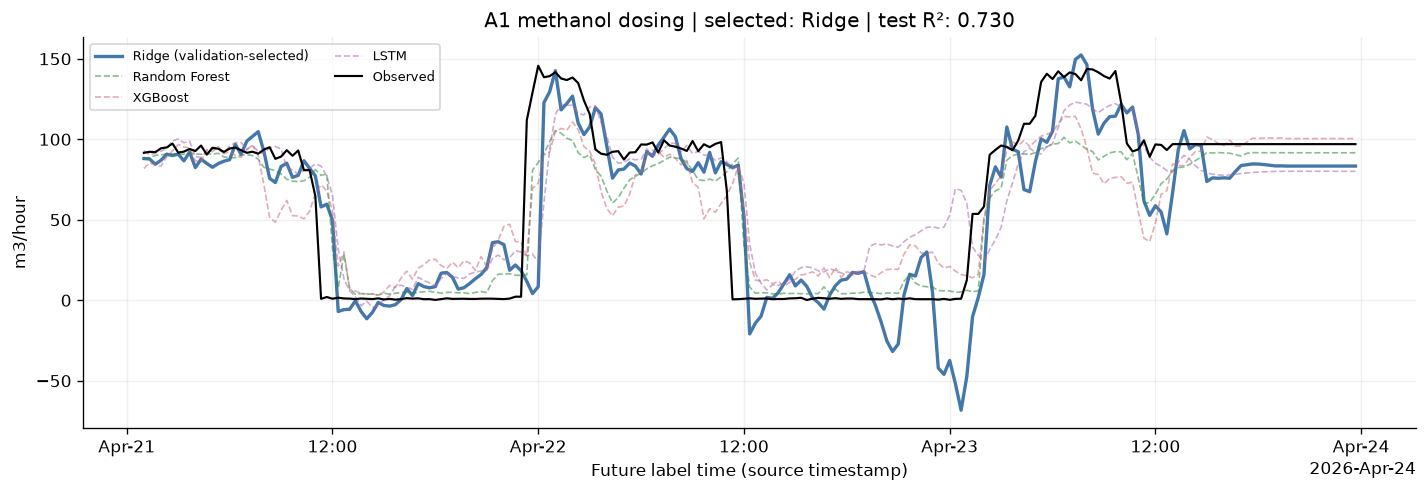

,algorithm,n,MAE,RMSE,R2,unit
158,Ridge,213,17.871515,26.470019,0.730146,m3/hour
161,Random Forest,213,15.216768,23.183888,0.792989,m3/hour
164,XGBoost,213,20.811870,27.618834,0.706214,m3/hour
167,LSTM,213,19.750141,27.882788,0.700572,m3/hour


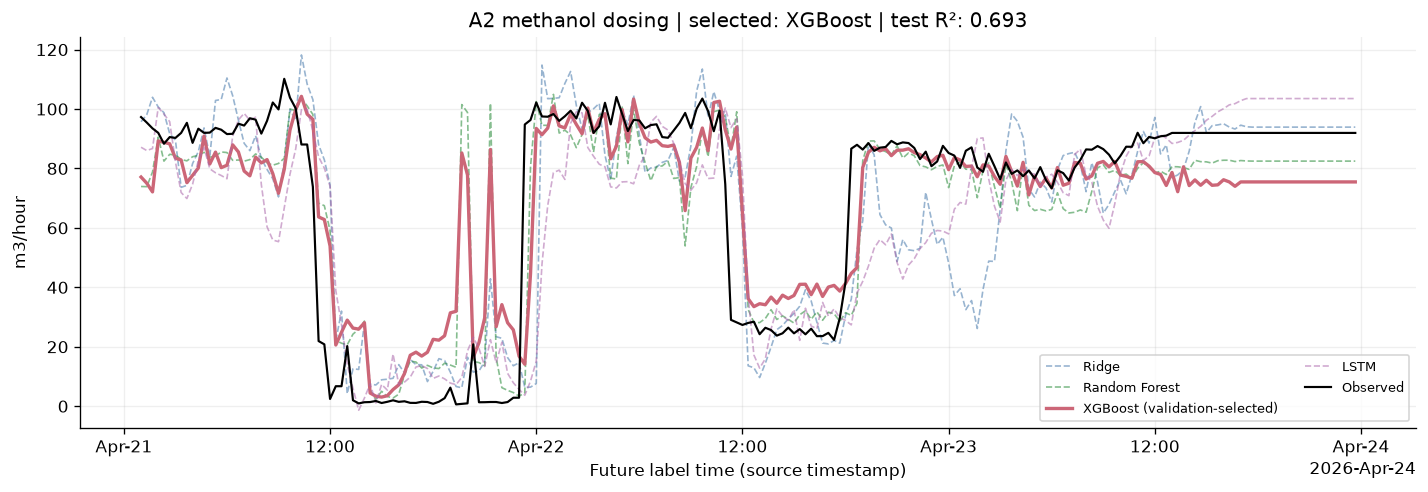

,algorithm,n,MAE,RMSE,R2,unit
182,Ridge,213,14.490826,21.816175,0.624618,m3/hour
185,Random Forest,213,12.471240,20.118818,0.680757,m3/hour
188,XGBoost,213,13.529343,19.716478,0.693398,m3/hour
191,LSTM,213,15.590635,22.658731,0.595063,m3/hour


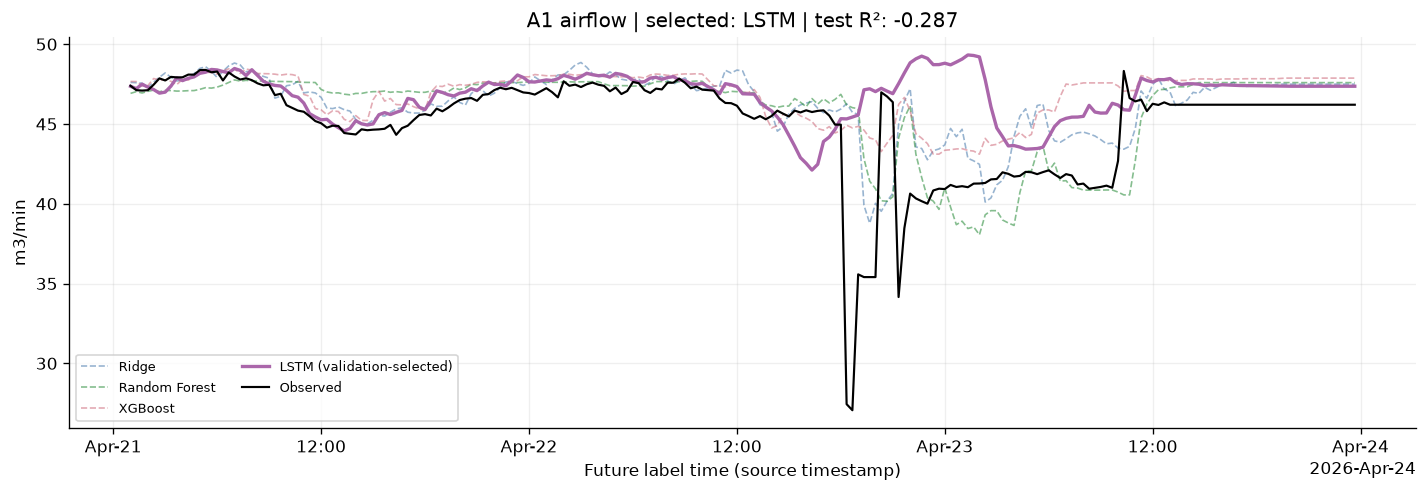

,algorithm,n,MAE,RMSE,R2,unit
146,Ridge,211,1.557245,2.801729,0.240209,m3/min
149,Random Forest,211,1.564249,2.821518,0.229438,m3/min
152,XGBoost,211,1.902007,3.096374,0.071998,m3/min
155,LSTM,211,2.025027,3.646666,-0.287165,m3/min


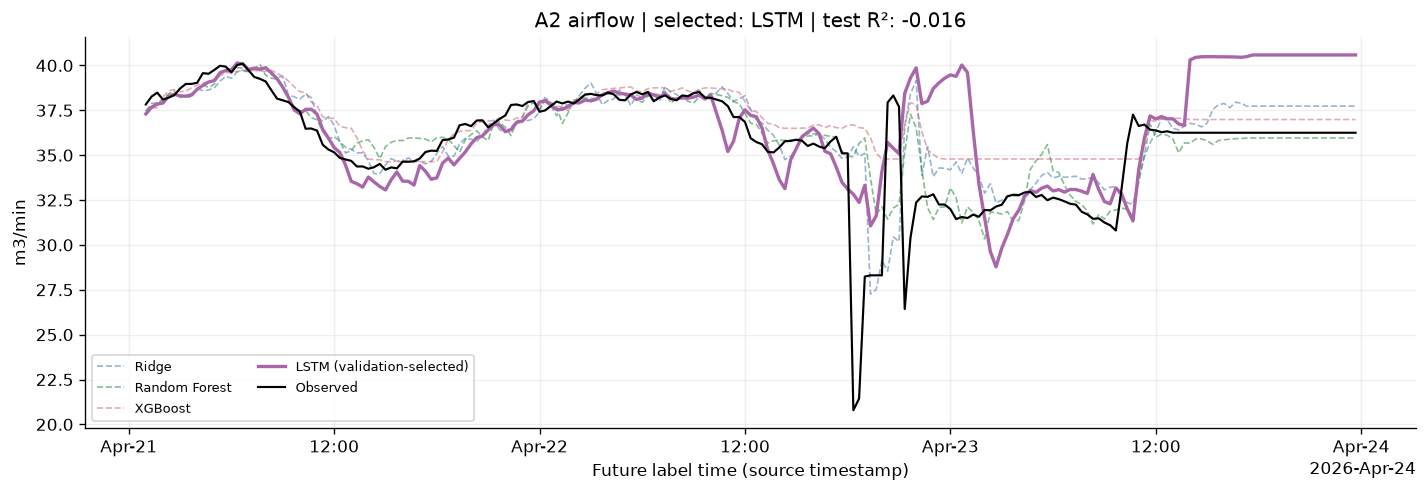

,algorithm,n,MAE,RMSE,R2,unit
170,Ridge,211,1.286218,2.337257,0.371420,m3/min
173,Random Forest,211,0.989849,2.102144,0.491522,m3/min
176,XGBoost,211,1.434673,2.491754,0.285574,m3/min
179,LSTM,211,1.899255,2.971203,-0.015808,m3/min


In [5]:
colors = {'Ridge': '#4477AA', 'Random Forest': '#228833', 'XGBoost': '#CC6677', 'LSTM': '#AA66AA'}
for name in ORDER:
    p = pd.read_csv(ASSETS / f'{name}_test_predictions.csv', parse_dates=['origin', 'target_time'])
    assert p['split'].eq('test').all()
    assert p.origin.ge(pd.Timestamp('2026-04-21')).all() and p.target_time.lt(pd.Timestamp('2026-04-24')).all()
    assert (p.target_time - p.origin).eq(pd.Timedelta(hours=1)).all()
    winner = winners.set_index('model').loc[name, 'algorithm']
    h = headline.set_index('model').loc[name]
    fig, ax = plt.subplots(figsize=(12, 4.2))
    for algorithm in ALGORITHMS:
        ax.plot(p.target_time, p[algorithm], color=colors[algorithm],
                linewidth=2 if algorithm == winner else 1, alpha=1 if algorithm == winner else .55,
                linestyle='-' if algorithm == winner else '--',
                label=algorithm + (' (validation-selected)' if algorithm == winner else ''))
    ax.plot(p.target_time, p.target, color='black', linewidth=1.3, label='Observed', zorder=5)
    score = 'undefined' if pd.isna(h['Test R2']) else f"{h['Test R2']:.3f}"
    ax.set(title=f"{LABELS[name]} | selected: {winner} | test R²: {score}", ylabel=h['unit'], xlabel='Future label time (source timestamp)')
    locator = mdates.AutoDateLocator(minticks=4, maxticks=8)
    ax.xaxis.set_major_locator(locator)
    ax.xaxis.set_major_formatter(mdates.ConciseDateFormatter(locator))
    ax.grid(alpha=.2)
    ax.legend(loc='best', fontsize=8, ncol=2)
    fig.tight_layout()
    fig.savefig(ASSETS / f'{name}_test_comparison.png', dpi=170)
    plt.show()
    display(tuned.loc[tuned.model.eq(name) & tuned['split'].eq('test'), ['algorithm', 'n', 'MAE', 'RMSE', 'R2', 'unit']].round(6))

## Real operating variation and target-specific interpretation

- **Ammonium:** validation-selected XGBoost has test R² approximately zero. Its absolute errors are small in the narrow test concentration range, but useful prediction of variation is not established. Training includes high-concentration events absent from validation/testing. Preserve these real operational events and evaluate performance separately across operating conditions before considering any quality-based exclusions.
- **Nitrate:** the recorded target is constant at 5 mg-N/L. Ridge and the tree models have zero error; LSTM can deviate. Undefined R² and zero error for a constant signal provide no evidence of forecasting changing nitrate concentrations.
- **Methanol:** validation-selected A1 Ridge and A2 XGBoost retain positive test R², about 0.730 and 0.693. This is the strongest result in the current study. Forecasting recorded dosing does not demonstrate optimal dosing or chemical savings.
- **Airflow:** validation-selected LSTMs have high validation R² but negative test R². Other algorithms have positive test R², as the full comparison shows, but selecting them after inspecting the test would be retrospective selection. The validation/test discrepancy is consistent with sensitivity to changing operating conditions; it does not prove a specific physical cause.

The plant owner confirms that the raw variability reflects real operation. Do not relabel unusual periods as faults without independent evidence. Real variability is part of the forecasting task, including transitions and uncommon events.

In [6]:
distributions = pd.read_csv(ASSETS / 'target_distributions.csv')
display(distributions.loc[distributions.model.eq('eff_nh3_n')].round(6))
audit = json.loads((ASSETS / 'verification.json').read_text())
display(audit)
assert all(value is True for key, value in audit.items() if key != 'targets_verified')
print('Verified source audit: unchanged labels/splits, validation-only selection and saved-model prediction reproducibility.')

,model,split,minimum,median,p95,p99,maximum
0,eff_nh3_n,train,0.142600,0.1938,0.214600,1.881630,7.6522
1,eff_nh3_n,validation,0.172422,0.1964,0.214733,0.222328,0.2250
2,eff_nh3_n,test,0.168600,0.2012,0.214300,0.223200,0.2236


{'targets_verified': ['a1_air_flow',
  'a1_ch3oh_flow',
  'a2_air_flow',
  'a2_ch3oh_flow',
  'eff_nh3_n',
  'eff_no3_n'],
 'all_sample_labels_and_splits_unchanged': True,
 'validation_error_nonincreasing_for_every_model': True,
 'serialized_models_reproduce_predictions': True,
 'algorithm_selection_matches_validation_only': True}

Verified source audit: unchanged labels/splits, validation-only selection and saved-model prediction reproducibility.


## Report conclusion and next evaluation

This is a reportable experimental multivariate time-series forecasting study using real treatment-plant observations. Methanol forecasts generalize more consistently than ammonium or airflow in the fixed April 21–23 evaluation. Expanding history benefits several candidates, while hyperparameter tuning does not consistently improve test performance. High training or validation R² alone is insufficient for operational acceptance.

Before operational adoption, compare against persistence on these same labels, evaluate multiple chronological validation windows, and confirm the frozen procedure on a new later operating period. Evaluate normal operation and transitions separately, preserving their observations. Confirm instrument units and an operationally meaningful error criterion. The study does not establish optimized aeration setpoints, dosing recommendations, energy savings or chemical savings.

## Evidence and reproduction

- Result snapshots and SHA-256 provenance: `docs/assets/current_forecasts/provenance.json`.
- Feature selection: `Sensor_Configurations.xlsx`, saved feature configuration, and training workbook reader.
- Preparation: `python -m src.training.expand_history`; full-history inputs remain separate from original exports.
- Expanded training: see `src/training/README.md` for the explicit data/mask/output arguments.
- Tuning: `python -m src.training.tune`; audit: `python -m src.training.audit_tuning`.
- This notebook replays saved outputs, not model fitting. Its portable snapshots permit review even when ignored `data/training` artifacts are unavailable.
- Slide content: `docs/forecast_results_slides.md`. Original notebook 03–05 experiments remain historical evidence, not the source of these revised metrics.